# CREMA-D Speech Emotion Recognition - ONE notebook (upload `AudioWAV.zip` once, run top to bottom)
**Part 1** data + folds + feature comparison + Fisher/Bat selection + frozen WavLM probe
**Part 2** fine-tuned WavLM Transformer (actor-independent 5-fold)
**Part 3** SHAP vs attention explainability + final report + one-click download of all results.

Use a GPU runtime (T4). Everything is shared through variables and `/content/cache`, so nothing needs re-uploading.
Quick check: set `FOLDS_TO_RUN=[0]` in Part 2 (~15 min); full 5 folds take ~1.5 h.

In [1]:
%pip install -q librosa soundfile transformers shap

Note: you may need to restart the kernel to use updated packages.


In [8]:
import os, json, time, math, warnings, numpy as np, pandas as pd
warnings.filterwarnings("ignore")
# ---- leave these as they are on Colab (env vars are only used for offline testing) ----
try:
    import google.colab
    DEFAULT_BASE = "/content"
except ImportError:
    DEFAULT_BASE = os.getcwd()
BASE  = os.environ.get("SER_BASE", DEFAULT_BASE)
DEBUG = os.environ.get("SER_DEBUG", "0") == "1"
AUDIO_ZIP = f"{BASE}/AudioWAV.zip"            # the CREMA-D zip you uploaded
UNZIP_TO  = f"{BASE}/crema_data"
CACHE, RES, MODELS = f"{BASE}/cache", f"{BASE}/results", f"{BASE}/models"
for d in (CACHE, RES, MODELS): os.makedirs(d, exist_ok=True)
EMOS = ["ANG","DIS","FEA","HAP","NEU","SAD"]
SEED = 42
import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
from IPython.display import display, Image
def show(path): display(Image(filename=path))

# PART 1 - Data preparation, feature-extraction comparison, Fisher/Bat selection, frozen-WavLM probing
Real CREMA-D. **Actor-independent** evaluation (5-fold GroupKFold by actor ID) everywhere.
Outputs go to `/content/results` (csv + png).

In [9]:
import zipfile, glob, librosa, soundfile

def find_audio_dir(root):
    for r, _, fs in os.walk(root):
        if any(f.lower().endswith(".wav") for f in fs): return r

if "SER_AUDIO" in os.environ:
    AUDIO_DIR = os.environ["SER_AUDIO"]
    if not os.path.isdir(AUDIO_DIR) or not find_audio_dir(AUDIO_DIR):
        raise FileNotFoundError(f"SER_AUDIO must point to a directory containing WAV files: {AUDIO_DIR}")
else:
    AUDIO_DIR = find_audio_dir(UNZIP_TO) if os.path.isdir(UNZIP_TO) else None
    if not AUDIO_DIR:
        zip_candidates = [AUDIO_ZIP, os.path.join(os.getcwd(), "AudioWAV.zip")]
        AUDIO_ZIP = next((path for path in dict.fromkeys(zip_candidates) if zipfile.is_zipfile(path)), None)
        if not AUDIO_ZIP:
            searched = ", ".join(dict.fromkeys(zip_candidates))
            raise FileNotFoundError(
                "AudioWAV.zip is missing or invalid. Put it in the runtime data folder "
                f"({BASE}) or current working directory, or set SER_BASE/SER_AUDIO. Checked: {searched}"
            )
        os.makedirs(UNZIP_TO, exist_ok=True)
        with zipfile.ZipFile(AUDIO_ZIP) as archive:
            archive.extractall(UNZIP_TO)
        AUDIO_DIR = find_audio_dir(UNZIP_TO)
        if not AUDIO_DIR:
            raise FileNotFoundError(f"No .wav files were found after extracting {AUDIO_ZIP} to {UNZIP_TO}")

print("audio dir:", AUDIO_DIR)

audio dir: c:\Users\shrey\Downloads\vedproject/crema_data\AudioWAV


## 1. Metadata and actor-independent folds

In [10]:
from sklearn.model_selection import GroupKFold
rows=[]
for f in sorted(glob.glob(os.path.join(AUDIO_DIR,"*.wav"))):
    p=os.path.basename(f)[:-4].split("_")
    if len(p)>=3 and p[2] in EMOS: rows.append((f,int(p[0]),EMOS.index(p[2]),p[2]))
meta=pd.DataFrame(rows,columns=["path","actor","label","emo"])
meta["fold"]=-1
for k,(tr,te) in enumerate(GroupKFold(5).split(meta,meta.label,meta.actor)): meta.loc[te,"fold"]=k
for k in range(5):   # proof that no actor is shared between train and test
    assert not set(meta[meta.fold==k].actor) & set(meta[meta.fold!=k].actor)
meta.to_csv(f"{CACHE}/meta.csv",index=False)
print(len(meta),"clips,",meta.actor.nunique(),"actors"); display(pd.crosstab(meta.fold,meta.emo))

7442 clips, 91 actors


emo,ANG,DIS,FEA,HAP,NEU,SAD
fold,,,,,,
0,252,252,252,252,216,252
1,252,252,252,252,215,252
2,252,252,252,252,215,252
3,264,264,264,264,226,264
4,251,251,251,251,215,251


## 2. Waveform cache (16 kHz, first 3.5 s) - shared with notebooks 2 and 3

In [11]:
SR, MAXS = 16000, 56000
if os.path.exists(f'{CACHE}/wave.npy') and os.path.exists(f'{CACHE}/lens.npy'):
    wave=np.load(f'{CACHE}/wave.npy'); lens=np.load(f'{CACHE}/lens.npy'); print('loaded waveform cache')
else:
    wave=np.zeros((len(meta),MAXS),np.float32); lens=np.zeros(len(meta),np.int64)
    for i,p in enumerate(meta.path):
        y,_=librosa.load(p,sr=SR); y,_=librosa.effects.trim(y,top_db=30); y=y[:MAXS]
        wave[i,:len(y)]=y; lens[i]=len(y)
        if i%1500==0: print("loaded",i,flush=True)
    np.save(f"{CACHE}/wave.npy",wave); np.save(f"{CACHE}/lens.npy",lens)
    print("mean duration (s): %.2f"%(lens.mean()/SR))

loaded 0
loaded 1500
loaded 3000
loaded 4500
loaded 6000
mean duration (s): 2.38


## 3. Classical features (utterance statistics): MFCC-40, MFCC+d+dd (120), Log-Mel-64

In [12]:
HOP=320
def stats(M): return np.concatenate([M.mean(1),M.std(1)])
S_mfcc,S_mfccd,S_lmel=[],[],[]
for i in range(len(meta)):
    y=librosa.effects.preemphasis(wave[i,:lens[i]],coef=0.95)
    lm=librosa.power_to_db(librosa.feature.melspectrogram(y=y,sr=SR,n_fft=512,hop_length=HOP,n_mels=64))
    mf=librosa.feature.mfcc(S=lm,n_mfcc=40); d1=librosa.feature.delta(mf,width=5,mode="nearest"); d2=librosa.feature.delta(mf,order=2,width=5,mode="nearest")
    S_mfcc.append(stats(mf)); S_mfccd.append(stats(np.vstack([mf,d1,d2]))); S_lmel.append(stats(lm))
S_mfcc,S_mfccd,S_lmel=[np.array(a,np.float32) for a in (S_mfcc,S_mfccd,S_lmel)]
np.savez_compressed(f"{CACHE}/classical_stats.npz",mfcc=S_mfcc,mfccd=S_mfccd,lmel=S_lmel); print(S_mfcc.shape,S_mfccd.shape,S_lmel.shape)

(7442, 80) (7442, 240) (7442, 128)


In [13]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score
y=meta.label.values; g=meta.actor.values; fold=meta.fold.values
def cv_eval(S, make_clf):
    a,u,f=[],[],[]
    for k in range(5):
        tr,te=fold!=k,fold==k; sc=StandardScaler().fit(S[tr]); p=make_clf().fit(sc.transform(S[tr]),y[tr]).predict(sc.transform(S[te]))
        a.append(accuracy_score(y[te],p)); u.append(balanced_accuracy_score(y[te],p)); f.append(f1_score(y[te],p,average="macro"))
    return np.mean(a),np.std(a),np.mean(u),np.mean(f)
rows=[]
for name,S in [("MFCC-40",S_mfcc),("MFCC+d+dd (120)",S_mfccd),("Log-Mel-64",S_lmel)]:
    a,s,u,f=cv_eval(S,lambda:SVC(C=10,gamma="scale")); rows.append(dict(features=name,acc=a,acc_std=s,UA=u,macroF1=f)); print(rows[-1],flush=True)
fe=pd.DataFrame(rows); fe.to_csv(f"{RES}/feature_extraction_comparison.csv",index=False)
plt.figure(figsize=(6,4)); plt.bar(fe.features,fe.acc*100,yerr=fe.acc_std*100,color=["#4c78a8","#2ca02c","#f58518"]); plt.ylabel("Actor-independent accuracy (%)")
plt.title("Classical feature comparison (SVM)"); plt.xticks(rotation=10); plt.tight_layout(); plt.savefig(f"{RES}/feature_extraction_comparison.png",dpi=150); plt.show()

{'features': 'MFCC-40', 'acc': np.float64(0.4941711674679429), 'acc_std': np.float64(0.017038990227186915), 'UA': np.float64(0.49205755012058916), 'macroF1': np.float64(0.48975337507060257)}
{'features': 'MFCC+d+dd (120)', 'acc': np.float64(0.499319025735154), 'acc_std': np.float64(0.018817078678953342), 'UA': np.float64(0.4983358318775995), 'macroF1': np.float64(0.4944815348863866)}
{'features': 'Log-Mel-64', 'acc': np.float64(0.4971765189681567), 'acc_std': np.float64(0.017597568015368544), 'UA': np.float64(0.49677516851179887), 'macroF1': np.float64(0.4924374878576083)}


## 4. Fisher vs Bat vs Fisher+Bat channel selection (on MFCC+d+dd channels, selection uses training actors only)

In [14]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
C=120
def fisher_scores(S,yy):
    mu=S.mean(0); num=0; den=0
    for c in np.unique(yy):
        Sc=S[yy==c]; num=num+len(Sc)*(Sc.mean(0)-mu)**2; den=den+len(Sc)*Sc.var(0)
    return num/(den+1e-9)
def fast_cv(S,yy,gg,cols,k=3):
    acc=[]
    for tr,te in GroupKFold(k).split(S,yy,gg):
        sc=StandardScaler().fit(S[tr][:,cols]); acc.append(LDA().fit(sc.transform(S[tr][:,cols]),yy[tr]).score(sc.transform(S[te][:,cols]),yy[te]))
    return float(np.mean(acc))
def bat_select(S,yy,gg,cand,pop=12,iters=15,alpha=0.005,seed=SEED):
    rng=np.random.default_rng(seed); n=len(cand)
    cols=lambda m: (lambda ch:np.concatenate([ch,ch+C]))(np.array(cand)[m.astype(bool)])
    fit=lambda m: 0.0 if m.sum()<3 else fast_cv(S,yy,gg,cols(m))-alpha*m.mean()
    X=(rng.random((pop,n))<0.5).astype(int); V=np.zeros((pop,n)); F_=np.array([fit(x) for x in X]); b=X[F_.argmax()].copy(); bf=F_.max(); A=np.full(pop,0.9)
    for it in range(iters):
        for i in range(pop):
            V[i]+=(X[i]-b)*rng.random(); new=(rng.random(n)<1/(1+np.exp(-V[i]))).astype(int)
            if rng.random()>0.5: new=b.copy(); new[rng.random(n)<0.05]^=1
            fn=fit(new)
            if fn>=F_[i] and rng.random()<A[i]: X[i],F_[i]=new,fn; A[i]*=0.95
            if fn>bf: b,bf=new.copy(),fn
    return np.array(cand)[b.astype(bool)]
def select(method,S,yy,gg):
    fs=fisher_scores(S,yy); chf=fs[:C]+fs[C:]
    if method=="fisher": return np.argsort(-chf)[:40]
    if method=="bat": return bat_select(S,yy,gg,np.arange(C))
    if method=="fisher+bat": return bat_select(S,yy,gg,np.argsort(-chf)[:60])
    return np.arange(C)
rows=[]; store={}
for method in ["all 120","fisher","bat","fisher+bat"]:
    a,f,t,n=[],[],[],[]
    for k in range(5):
        tr,te=fold!=k,fold==k; t0=time.time(); ch=select(method,S_mfccd[tr],y[tr],g[tr]); t.append(time.time()-t0); n.append(len(ch)); store[f"{method}|fold{k}"]=[int(c) for c in ch]
        cols=np.concatenate([ch,ch+C]); sc=StandardScaler().fit(S_mfccd[tr][:,cols]); p=SVC(C=10,gamma="scale").fit(sc.transform(S_mfccd[tr][:,cols]),y[tr]).predict(sc.transform(S_mfccd[te][:,cols]))
        a.append(accuracy_score(y[te],p)); f.append(f1_score(y[te],p,average="macro"))
    rows.append(dict(method=method,acc=np.mean(a),acc_std=np.std(a),macroF1=np.mean(f),avg_channels=np.mean(n),selection_time_s=np.mean(t))); print(rows[-1],flush=True)
fs_df=pd.DataFrame(rows); fs_df.to_csv(f"{RES}/feature_selection_comparison.csv",index=False); json.dump(store,open(f"{RES}/selected_channels.json","w"))
fig,ax=plt.subplots(1,2,figsize=(9,4)); ax[0].bar(fs_df.method,fs_df.acc*100,yerr=fs_df.acc_std*100,color="#4c78a8"); ax[0].set_title("Accuracy (%)")
ax[1].bar(fs_df.method,fs_df.selection_time_s,color="#f58518"); ax[1].set_title("Selection time (s)"); plt.tight_layout(); plt.savefig(f"{RES}/feature_selection_comparison.png",dpi=150); plt.show()

{'method': 'all 120', 'acc': np.float64(0.499319025735154), 'acc_std': np.float64(0.018817078678953342), 'macroF1': np.float64(0.4944815348863866), 'avg_channels': np.float64(120.0), 'selection_time_s': np.float64(0.005480813980102539)}
{'method': 'fisher', 'acc': np.float64(0.5041346975813169), 'acc_std': np.float64(0.018709524330064543), 'macroF1': np.float64(0.49865502036749304), 'avg_channels': np.float64(40.0), 'selection_time_s': np.float64(0.007012128829956055)}
{'method': 'bat', 'acc': np.float64(0.4959418959492898), 'acc_std': np.float64(0.015109167794934052), 'macroF1': np.float64(0.49100887641755), 'avg_channels': np.float64(64.8), 'selection_time_s': np.float64(40.78099584579468)}
{'method': 'fisher+bat', 'acc': np.float64(0.5097203941144941), 'acc_std': np.float64(0.006498868117046252), 'macroF1': np.float64(0.5056051285559768), 'avg_channels': np.float64(37.6), 'selection_time_s': np.float64(24.33271222114563)}


## 5. Pretrained WavLM as a *feature extractor* (frozen): layer-wise probing

In [15]:
import torch, torch.nn as nn, torch.nn.functional as F
from transformers import WavLMModel, WavLMConfig
MODEL_NAME = "microsoft/wavlm-base-plus"     # try "microsoft/wavlm-large" for higher accuracy (slower, needs batch 8)
def build_backbone():
    if DEBUG:   # tiny random model, only for offline code testing
        cfg = WavLMConfig(hidden_size=32, num_hidden_layers=2, num_attention_heads=2, intermediate_size=64,
                          conv_dim=(16,)*7, num_feat_extract_layers=7, num_buckets=32, max_bucket_distance=64, num_conv_pos_embeddings=8, num_conv_pos_embedding_groups=2, layerdrop=0.0)
        return WavLMModel(cfg)
    return WavLMModel.from_pretrained(MODEL_NAME, apply_spec_augment=False, layerdrop=0.0)   # no augmentation, as requested
def prep(x_np, l_np):
    """per-utterance zero-mean/unit-variance normalisation over the real (unpadded) samples"""
    x = torch.as_tensor(x_np, dtype=torch.float32); l = torch.as_tensor(l_np).long()
    m = (torch.arange(x.shape[1])[None] < l[:, None]).float()
    mean = (x*m).sum(1, keepdim=True)/l[:, None]; var = (((x-mean)*m)**2).sum(1, keepdim=True)/l[:, None]
    return ((x-mean)/(var.sqrt()+1e-5))*m, l

In [16]:
dev="cuda" if torch.cuda.is_available() else "cpu"; enc=build_backbone().to(dev).eval(); NL=enc.config.num_hidden_layers+1
emb=np.zeros((len(meta),NL,2*enc.config.hidden_size),np.float16)
with torch.no_grad():
    for s in range(0,len(meta),32):
        idx=np.arange(s,min(s+32,len(meta))); x,l=prep(wave[idx],lens[idx]); hs=enc(x.to(dev),output_hidden_states=True).hidden_states
        T=hs[0].shape[1]; fl=torch.clamp((l-400)//320+1,1,T).to(dev); m=(torch.arange(T,device=dev)[None]<fl[:,None]).float().unsqueeze(-1)
        for j,h in enumerate(hs):
            mean=(h*m).sum(1)/m.sum(1); std=(((h-mean[:,None])**2*m).sum(1)/m.sum(1)).sqrt(); emb[idx,j]=torch.cat([mean,std],1).float().cpu().numpy()
        if s%640==0: print("embedded",s,flush=True)
np.save(f"{CACHE}/wavlm_frozen_emb.npy",emb); del enc; torch.cuda.empty_cache() if dev=="cuda" else None

config.json:   0%|          | 0.00/2.23k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  378MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

embedded 0
embedded 640
embedded 1280
embedded 1920
embedded 2560
embedded 3200
embedded 3840
embedded 4480
embedded 5120
embedded 5760
embedded 6400
embedded 7040


In [17]:
from sklearn.linear_model import LogisticRegression
layers=sorted(set([1,NL//4,NL//2,3*NL//4,NL-1])); rows=[]
for L in layers:
    a,s,u,f=cv_eval(emb[:,L].astype(np.float32),lambda:LogisticRegression(C=0.5,max_iter=300)); rows.append(dict(layer=L,acc=a,acc_std=s,UA=u,macroF1=f)); print(rows[-1],flush=True)
pr=pd.DataFrame(rows); pr.to_csv(f"{RES}/wavlm_frozen_layer_probe.csv",index=False)
plt.figure(figsize=(6,4)); plt.errorbar(pr.layer,pr.acc*100,yerr=pr.acc_std*100,marker="o"); plt.xlabel("WavLM layer"); plt.ylabel("Actor-independent accuracy (%)"); plt.title("Frozen WavLM layer-wise probe")
plt.tight_layout(); plt.savefig(f"{RES}/wavlm_frozen_layer_probe.png",dpi=150); plt.show()

{'layer': 1, 'acc': np.float64(0.5670513194616061), 'acc_std': np.float64(0.023064921713987427), 'UA': np.float64(0.5673778110761405), 'macroF1': np.float64(0.5671384319842823)}
{'layer': 3, 'acc': np.float64(0.6280958497150119), 'acc_std': np.float64(0.028521645408649335), 'UA': np.float64(0.6299634866997085), 'macroF1': np.float64(0.629842242498275)}
{'layer': 6, 'acc': np.float64(0.6803587812156915), 'acc_std': np.float64(0.0186901285197652), 'UA': np.float64(0.6830213442317362), 'macroF1': np.float64(0.6822346392369754)}
{'layer': 9, 'acc': np.float64(0.6627711118736197), 'acc_std': np.float64(0.01840216334421974), 'UA': np.float64(0.6655736012525655), 'macroF1': np.float64(0.6652635099380845)}
{'layer': 12, 'acc': np.float64(0.6230309959930922), 'acc_std': np.float64(0.017816429708338747), 'UA': np.float64(0.6261069620889372), 'macroF1': np.float64(0.625243818133673)}


## 6. Summary of notebook 1

In [18]:
summ=pd.concat([fe.assign(group="classical")[["group","features","acc","acc_std","macroF1"]].rename(columns={"features":"name"}),
 fs_df.assign(group="selection (MFCC+d+dd, SVM)",name=lambda d:"Fisher/Bat: "+d.method)[["group","name","acc","acc_std","macroF1"]],
 pr.assign(group="frozen WavLM (LogReg)",name=lambda d:"layer "+d.layer.astype(str))[["group","name","acc","acc_std","macroF1"]]])
summ.to_csv(f"{RES}/notebook1_summary.csv",index=False); display(summ.round(4)); print("PART 1 DONE")

,group,name,acc,acc_std,macroF1
0,classical,MFCC-40,0.4942,0.0170,0.4898
1,classical,MFCC+d+dd (120),0.4993,0.0188,0.4945
2,classical,Log-Mel-64,0.4972,0.0176,0.4924
0,"selection (MFCC+d+dd, SVM)",Fisher/Bat: all 120,0.4993,0.0188,0.4945
1,"selection (MFCC+d+dd, SVM)",Fisher/Bat: fisher,0.5041,0.0187,0.4987
2,"selection (MFCC+d+dd, SVM)",Fisher/Bat: bat,0.4959,0.0151,0.4910
3,"selection (MFCC+d+dd, SVM)",Fisher/Bat: fisher+bat,0.5097,0.0065,0.5056
0,frozen WavLM (LogReg),layer 1,0.5671,0.0231,0.5671
1,frozen WavLM (LogReg),layer 3,0.6281,0.0285,0.6298
2,frozen WavLM (LogReg),layer 6,0.6804,0.0187,0.6822


PART 1 DONE


# PART 2 - Fine-tuned WavLM (Transformer) for CREMA-D emotion recognition
Actor-independent 5-fold evaluation (same folds as notebook 1). 
Design: pretrained WavLM-base+ Transformer, fine-tuned end-to-end, learnable layer-weighted sum, attentive pooling, fp16, layer-wise learning rates,
warm-up + cosine schedule, label smoothing, early stopping on *validation actors* (never on test actors). No data augmentation.
Set `FOLDS_TO_RUN=[0]` for a quick single-fold run (~15 min on a T4); all 5 folds take roughly 1.5 h.

In [19]:
class SER(nn.Module):
    """WavLM (fine-tuned) -> learnable weighted sum of ALL layers -> attentive pooling -> MLP classifier"""
    def __init__(self, n_cls=6, hid=256, p=0.2):
        super().__init__()
        self.enc=build_backbone(); self.enc.freeze_feature_encoder()
        L=self.enc.config.num_hidden_layers+1; D=self.enc.config.hidden_size
        self.lw=nn.Parameter(torch.zeros(L)); self.att=nn.Sequential(nn.Linear(D,128),nn.Tanh(),nn.Linear(128,1))
        self.head=nn.Sequential(nn.LayerNorm(D),nn.Dropout(p),nn.Linear(D,hid),nn.GELU(),nn.Dropout(p),nn.Linear(hid,n_cls))
    def forward(self,x,l):
        H=torch.stack(self.enc(x,output_hidden_states=True).hidden_states,0); w=torch.softmax(self.lw,0)
        h=(w[:,None,None,None]*H).sum(0); T=h.shape[1]
        fl=torch.clamp((l.to(x.device)-400)//320+1,1,T); m=torch.arange(T,device=x.device)[None]<fl[:,None]
        a=torch.softmax(self.att(h).squeeze(-1).float().masked_fill(~m,-1e4),1)          # attention-pooling weights (B,T)
        return self.head((a.unsqueeze(-1)*h.float()).sum(1)), a

In [20]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix, classification_report
meta=pd.read_csv(f"{CACHE}/meta.csv"); wave=np.load(f"{CACHE}/wave.npy"); lens=np.load(f"{CACHE}/lens.npy")
y=meta.label.values; actor=meta.actor.values; fold=meta.fold.values
dev="cuda" if torch.cuda.is_available() else "cpu"; use_amp=(dev=="cuda"); print("device:",dev)
# ----------------- hyper-parameters -----------------
FOLDS_TO_RUN=[0,1,2,3,4]
EPOCHS=12 if not DEBUG else 1; BS=16; LR_BACKBONE=3e-5; LR_HEAD=1e-3; WD=0.01; PATIENCE=4; N_VAL_ACTORS=8

device: cuda


In [22]:
@torch.no_grad()
def predict(model,idx,bs=32):
    model.eval(); P=[]
    for s in range(0,len(idx),bs):
        b=idx[s:s+bs]; x,l=prep(wave[b],lens[b])
        with torch.autocast("cuda",dtype=torch.float16,enabled=use_amp): lo,_=model(x.to(dev),l)
        P.append(torch.softmax(lo.float(),1).cpu().numpy())
    return np.concatenate(P)
def train_fold(f):
    torch.manual_seed(SEED+f); rng=np.random.default_rng(SEED+f)
    te=np.where(fold==f)[0]; trall=np.where(fold!=f)[0]; ua=np.unique(actor[trall]); va_actors=rng.choice(ua,N_VAL_ACTORS,replace=False)
    va=trall[np.isin(actor[trall],va_actors)]; tr=trall[~np.isin(actor[trall],va_actors)]
    model=SER().to(dev)
    bb=[p for n,p in model.named_parameters() if n.startswith("enc.") and p.requires_grad]; hd=[p for n,p in model.named_parameters() if not n.startswith("enc.")]
    opt=torch.optim.AdamW([{"params":bb,"lr":LR_BACKBONE},{"params":hd,"lr":LR_HEAD}],weight_decay=WD)
    steps=EPOCHS*math.ceil(len(tr)/BS); warm=int(0.1*steps)
    sched=torch.optim.lr_scheduler.LambdaLR(opt,lambda s: (s+1)/warm if s<warm else 0.5*(1+math.cos(math.pi*(s-warm)/max(1,steps-warm))))
    scaler=torch.amp.GradScaler("cuda",enabled=use_amp); best,bad,hist,state=-1,0,[],None
    for ep in range(EPOCHS):
        model.train(); perm=rng.permutation(tr); tl=0; t0=time.time()
        for s in range(0,len(perm),BS):
            b=perm[s:s+BS]; x,l=prep(wave[b],lens[b]); yb=torch.as_tensor(y[b]).to(dev)
            with torch.autocast("cuda",dtype=torch.float16,enabled=use_amp): lo,_=model(x.to(dev),l); loss=F.cross_entropy(lo.float(),yb,label_smoothing=0.1)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(),1.0); scaler.step(opt); scaler.update(); sched.step(); tl+=loss.item()*len(b)
        pv=predict(model,va).argmax(1); vua=balanced_accuracy_score(y[va],pv); hist.append((tl/len(tr),accuracy_score(y[va],pv),vua))
        print(f"fold {f} ep {ep+1}/{EPOCHS} loss {tl/len(tr):.3f} val_acc {hist[-1][1]:.3f} ({time.time()-t0:.0f}s)",flush=True)
        if vua>best: best,bad,state=vua,0,{k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        else:
            bad+=1
            if bad>=PATIENCE: break
    model.load_state_dict(state); prob=predict(model,te); torch.save(state,f"{MODELS}/fold{f}.pt")
    return te,prob,hist,state["lw"].numpy()

In [23]:
results,hists,lws,allp,ally=[],{},{},[],[]
for f in FOLDS_TO_RUN:
    t0=time.time(); te,prob,hist,lw=train_fold(f); pred=prob.argmax(1)
    m=dict(fold=f,acc=accuracy_score(y[te],pred),UA=balanced_accuracy_score(y[te],pred),macroF1=f1_score(y[te],pred,average="macro"),epochs_run=len(hist),time_min=(time.time()-t0)/60)
    results.append(m); print("RESULT",m,flush=True); hists[f]=hist; lws[f]=lw; allp+=list(pred); ally+=list(y[te])
    pd.DataFrame({"idx":te,"y":y[te],"pred":pred}).to_csv(f"{RES}/preds_fold{f}.csv",index=False)
    pd.DataFrame(results).to_csv(f"{RES}/finetune_fold_results.csv",index=False)     # saved after every fold
df=pd.DataFrame(results); display(df.round(4))
summary=pd.DataFrame({"mean":df[["acc","UA","macroF1"]].mean(),"std":df[["acc","UA","macroF1"]].std()}).round(4); summary.to_csv(f"{RES}/finetune_summary.csv"); display(summary)

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

fold 0 ep 1/12 loss 1.384 val_acc 0.736 (89s)
fold 0 ep 2/12 loss 0.988 val_acc 0.736 (86s)
fold 0 ep 3/12 loss 0.815 val_acc 0.787 (86s)
fold 0 ep 4/12 loss 0.691 val_acc 0.798 (88s)
fold 0 ep 5/12 loss 0.606 val_acc 0.809 (90s)
fold 0 ep 6/12 loss 0.552 val_acc 0.809 (88s)
fold 0 ep 7/12 loss 0.496 val_acc 0.809 (88s)
fold 0 ep 8/12 loss 0.472 val_acc 0.790 (87s)
fold 0 ep 9/12 loss 0.451 val_acc 0.809 (88s)
fold 0 ep 10/12 loss 0.442 val_acc 0.799 (87s)
fold 0 ep 11/12 loss 0.438 val_acc 0.810 (88s)
fold 0 ep 12/12 loss 0.437 val_acc 0.821 (88s)
RESULT {'fold': 0, 'acc': 0.7330623306233063, 'UA': 0.7362213403880071, 'macroF1': 0.7318467197771663, 'epochs_run': 12, 'time_min': 17.800154709815978}


Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

fold 1 ep 1/12 loss 1.358 val_acc 0.690 (89s)
fold 1 ep 2/12 loss 0.984 val_acc 0.708 (87s)
fold 1 ep 3/12 loss 0.823 val_acc 0.731 (88s)
fold 1 ep 4/12 loss 0.697 val_acc 0.744 (88s)
fold 1 ep 5/12 loss 0.612 val_acc 0.753 (89s)
fold 1 ep 6/12 loss 0.550 val_acc 0.733 (87s)
fold 1 ep 7/12 loss 0.502 val_acc 0.727 (87s)
fold 1 ep 8/12 loss 0.468 val_acc 0.744 (89s)
fold 1 ep 9/12 loss 0.450 val_acc 0.737 (87s)
RESULT {'fold': 1, 'acc': 0.7633898305084745, 'UA': 0.764968623108158, 'macroF1': 0.764417692616314, 'epochs_run': 9, 'time_min': 13.411624336242676}


Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

...

fold 3 ep 1/12 loss 1.359 val_acc 0.692 (87s)
fold 3 ep 2/12 loss 0.969 val_acc 0.765 (87s)
fold 3 ep 3/12 loss 0.792 val_acc 0.730 (87s)
fold 3 ep 4/12 loss 0.679 val_acc 0.741 (88s)
fold 3 ep 5/12 loss 0.598 val_acc 0.736 (86s)
fold 3 ep 6/12 loss 0.534 val_acc 0.720 (87s)
RESULT {'fold': 3, 'acc': 0.7335058214747736, 'UA': 0.7356529900777687, 'macroF1': 0.7371585223817515, 'epochs_run': 6, 'time_min': 8.900935486952465}


Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

fold 4 ep 1/12 loss 1.329 val_acc 0.653 (89s)
fold 4 ep 2/12 loss 0.961 val_acc 0.732 (88s)
fold 4 ep 3/12 loss 0.797 val_acc 0.732 (88s)
fold 4 ep 4/12 loss 0.675 val_acc 0.741 (88s)
fold 4 ep 5/12 loss 0.601 val_acc 0.760 (88s)
fold 4 ep 6/12 loss 0.542 val_acc 0.763 (88s)
fold 4 ep 7/12 loss 0.491 val_acc 0.780 (87s)
fold 4 ep 8/12 loss 0.464 val_acc 0.775 (88s)
fold 4 ep 9/12 loss 0.448 val_acc 0.770 (87s)
fold 4 ep 10/12 loss 0.438 val_acc 0.783 (89s)
fold 4 ep 11/12 loss 0.436 val_acc 0.777 (88s)
fold 4 ep 12/12 loss 0.434 val_acc 0.783 (88s)
RESULT {'fold': 4, 'acc': 0.7462585034013606, 'UA': 0.7504339232218413, 'macroF1': 0.7442826622431786, 'epochs_run': 12, 'time_min': 17.816553390026094}


,fold,acc,UA,macroF1,epochs_run,time_min
0,0,0.7331,0.7362,0.7318,12,17.8002
1,1,0.7634,0.7650,0.7644,9,13.4116
2,2,0.7932,0.7963,0.7923,12,17.8814
3,3,0.7335,0.7357,0.7372,6,8.9009
4,4,0.7463,0.7504,0.7443,12,17.8166


,mean,std
acc,0.7539,0.0252
UA,0.7567,0.0252
macroF1,0.7540,0.0247


In [24]:
cm=confusion_matrix(ally,allp,normalize="true"); fig,ax=plt.subplots(1,2,figsize=(13,4.8))
ax[0].imshow(cm,cmap="Blues",vmin=0,vmax=1); ax[0].set_xticks(range(6)); ax[0].set_yticks(range(6)); ax[0].set_xticklabels(EMOS); ax[0].set_yticklabels(EMOS); ax[0].set_title("Normalised confusion matrix (all test actors)")
for i in range(6):
    for j in range(6): ax[0].text(j,i,f"{cm[i,j]:.2f}",ha="center",va="center",color="white" if cm[i,j]>.5 else "black")
for f,h in hists.items(): ax[1].plot([q[1] for q in h],label=f"fold {f} val acc")
ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].set_title("Validation accuracy (validation actors)"); plt.tight_layout(); plt.savefig(f"{RES}/finetune_confusion_and_curves.png",dpi=150); plt.show()
rep=pd.DataFrame(classification_report(ally,allp,target_names=EMOS,output_dict=True)).T.round(3); rep.to_csv(f"{RES}/finetune_per_class_report.csv"); display(rep)
lwm=np.mean([torch.softmax(torch.tensor(v),0).numpy() for v in lws.values()],0); plt.figure(figsize=(6,3.5)); plt.bar(range(len(lwm)),lwm); plt.xlabel("WavLM layer"); plt.ylabel("learned weight (softmax)")
plt.title("Which layers the fine-tuned model uses"); plt.tight_layout(); plt.savefig(f"{RES}/finetune_layer_weights.png",dpi=150); plt.show()

,precision,recall,f1-score,support
ANG,0.795,0.880,0.835,1271.000
DIS,0.767,0.682,0.722,1271.000
FEA,0.720,0.622,0.668,1271.000
HAP,0.820,0.799,0.810,1271.000
NEU,0.785,0.871,0.826,1087.000
SAD,0.639,0.685,0.661,1271.000
accuracy,0.754,0.754,0.754,0.754
macro avg,0.754,0.757,0.754,7442.000
weighted avg,0.754,0.754,0.752,7442.000


In [25]:
# ---- comparison with everything from notebook 1 (only rows that exist) ----
rows=[]
p=f"{RES}/notebook1_summary.csv"
if os.path.exists(p):
    n1=pd.read_csv(p)
    for _,r in n1[n1.group.isin(["classical"])].iterrows(): rows.append((r["name"]+" + SVM",r.acc*100,r.acc_std*100))
    fz=n1[n1.group.str.startswith("frozen")]
    if len(fz): r=fz.loc[fz.acc.idxmax()]; rows.append(("Frozen WavLM ("+r["name"]+") + LogReg",r.acc*100,r.acc_std*100))
rows.append(("Fine-tuned WavLM Transformer (ours)",df.acc.mean()*100,df.acc.std()*100 if len(df)>1 else 0))
cmp_=pd.DataFrame(rows,columns=["model","acc","std"]); cmp_.to_csv(f"{RES}/final_model_comparison.csv",index=False)
plt.figure(figsize=(9,4)); plt.barh(cmp_.model,cmp_.acc,xerr=cmp_["std"],color=["#999"]*(len(cmp_)-1)+["#2ca02c"]); plt.xlabel("Actor-independent accuracy (%)"); plt.tight_layout(); plt.savefig(f"{RES}/final_model_comparison.png",dpi=150); plt.show(); display(cmp_.round(2))
print("PART 2 DONE")

,model,acc,std
0,MFCC-40 + SVM,49.42,1.70
1,MFCC+d+dd (120) + SVM,49.93,1.88
2,Log-Mel-64 + SVM,49.72,1.76
3,Frozen WavLM (layer 6) + LogReg,68.04,1.87
4,Fine-tuned WavLM Transformer (ours),75.39,2.52


PART 2 DONE


# PART 3 - Explainability: SHAP vs Transformer attention (per emotion) + final report
Uses the fold model saved in Part 2. For each emotion we explain correctly-classified **unseen-actor** clips:
* **SHAP** (`shap.KernelExplainer`) over 10 equal time segments of the utterance (segment removed = masked with silence) -> contribution of each segment to the predicted class
* **Attention**: the model's own attentive-pooling weights, binned into the same 10 segments
Then we measure the agreement (Spearman) between the two per emotion, and high- vs low-arousal emotions.

In [26]:
import shap
from scipy.stats import spearmanr
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
meta=pd.read_csv(f"{CACHE}/meta.csv"); wave=np.load(f"{CACHE}/wave.npy"); lens=np.load(f"{CACHE}/lens.npy"); y=meta.label.values; fold=meta.fold.values
dev="cuda" if torch.cuda.is_available() else "cpu"; use_amp=dev=="cuda"
FOLD=int(os.environ.get("SER_FOLD",0)); N_PER_EMO=15 if not DEBUG else 2; NSEG=10; NSAMPLES=200 if not DEBUG else 20
model=SER().to(dev); model.load_state_dict(torch.load(f"{MODELS}/fold{FOLD}.pt",map_location=dev)); model.eval()
te=np.where(fold==FOLD)[0]
@torch.no_grad()
def run(x_np,l_np,bs=64):
    P,A=[],[]
    for s in range(0,len(x_np),bs):
        x,l=prep(x_np[s:s+bs],l_np[s:s+bs])
        with torch.autocast("cuda",dtype=torch.float16,enabled=use_amp): lo,a=model(x.to(dev),l)
        P.append(torch.softmax(lo.float(),1).cpu().numpy()); A.append(a.float().cpu().numpy())
    return np.concatenate(P),np.concatenate(A)
P,_=run(wave[te],lens[te]); pred=P.argmax(1)
print(f"fold {FOLD} test: acc {accuracy_score(y[te],pred):.4f}  UA {balanced_accuracy_score(y[te],pred):.4f}  macroF1 {f1_score(y[te],pred,average='macro'):.4f}")
rng=np.random.default_rng(0); chosen={}
for e in range(6):
    ok=te[(y[te]==e)&(pred==e)]; chosen[e]=rng.choice(ok,min(N_PER_EMO,len(ok)),replace=False)
print({EMOS[e]:len(v) for e,v in chosen.items()})

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

fold 0 test: acc 0.7337  UA 0.7369  macroF1 0.7325
{'ANG': 15, 'DIS': 15, 'FEA': 15, 'HAP': 15, 'NEU': 15, 'SAD': 15}


In [27]:
def shap_segments(i,cls):
    n=int(lens[i]); b=np.linspace(0,n,NSEG+1).astype(int); w=wave[i]
    def f(Z):
        Z=np.asarray(Z); X=np.tile(w,(len(Z),1))
        for j in range(NSEG): X[np.where(Z[:,j]==0)[0],b[j]:b[j+1]]=0
        return run(X,np.full(len(Z),n))[0][:,cls]
    ex=shap.KernelExplainer(f,np.zeros((1,NSEG))); sv=ex.shap_values(np.ones((1,NSEG)),nsamples=NSAMPLES,silent=True)
    return np.asarray(sv).reshape(-1)[:NSEG]
def att_segments(i):
    _,a=run(wave[i:i+1],lens[i:i+1]); T=a.shape[1]; fl=int(np.clip((lens[i]-400)//320+1,1,T)); seg=np.array_split(a[0,:fl],NSEG)
    return np.array([s.mean() if len(s) else 0 for s in seg])
S_imp,A_imp,rho_clip,records={},{},{},[]
for e in range(6):
    sh,at,rc=[],[],[]
    if len(chosen[e])==0: S_imp[e],A_imp[e],rho_clip[e]=np.zeros(NSEG),np.ones(NSEG)/NSEG,np.nan; print(EMOS[e],"no correctly classified clips, skipped"); continue
    for i in chosen[e]:
        s=shap_segments(i,e); a=att_segments(i); sh.append(s); at.append(a/a.sum()); rc.append(spearmanr(s,a)[0])
    S_imp[e]=np.mean(sh,0); A_imp[e]=np.mean(at,0); rho_clip[e]=np.nanmean(rc); print(EMOS[e],"done, mean per-clip rho=%.3f"%rho_clip[e],flush=True)

ANG done, mean per-clip rho=0.404
DIS done, mean per-clip rho=0.290
FEA done, mean per-clip rho=0.357
HAP done, mean per-clip rho=0.347
NEU done, mean per-clip rho=-0.061
SAD done, mean per-clip rho=0.280


In [28]:
xs=np.linspace(0,100,NSEG,endpoint=False)+5; fig,ax=plt.subplots(2,3,figsize=(14,6.5))
for e in range(6):
    p=ax.flat[e]; s=S_imp[e]/(np.abs(S_imp[e]).max()+1e-12); a=A_imp[e]/A_imp[e].max()
    p.plot(xs,s,marker="o",label="SHAP (mean, normalised)"); p.plot(xs,a,marker="s",label="Attention pooling (normalised)")
    p.set_title(f"{EMOS[e]}  pooled rho={spearmanr(S_imp[e],A_imp[e])[0]:.2f}  per-clip rho={rho_clip[e]:.2f}"); p.set_xlabel("relative time in utterance (%)"); p.axhline(0,color="grey",lw=.5)
ax.flat[0].legend(fontsize=7); plt.tight_layout(); plt.savefig(f"{RES}/shap_vs_attention_time.png",dpi=150); plt.show()
ag=pd.DataFrame([dict(emotion=EMOS[e],arousal="high" if EMOS[e] in("ANG","HAP","FEA") else "low",n_clips=len(chosen[e]),spearman_pooled=spearmanr(S_imp[e],A_imp[e])[0],spearman_per_clip_mean=rho_clip[e],
      shap_peak_segment=int(np.argmax(S_imp[e])),attention_peak_segment=int(np.argmax(A_imp[e]))) for e in range(6)]); ag.to_csv(f"{RES}/shap_attention_agreement.csv",index=False); display(ag.round(3))
print(ag.groupby("arousal")[["spearman_pooled","spearman_per_clip_mean"]].mean().round(3))
plt.figure(figsize=(8,3.5)); hm=np.array([S_imp[e]/(np.abs(S_imp[e]).max()+1e-12) for e in range(6)]); plt.imshow(hm,aspect="auto",cmap="RdBu_r",vmin=-1,vmax=1); plt.colorbar(label="normalised SHAP")
plt.yticks(range(6),EMOS); plt.xlabel("time segment (1-10)"); plt.title("SHAP time-segment importance per emotion"); plt.tight_layout(); plt.savefig(f"{RES}/shap_time_heatmap.png",dpi=150); plt.show()

,emotion,arousal,n_clips,spearman_pooled,spearman_per_clip_mean,shap_peak_segment,attention_peak_segment
0,ANG,high,15,0.697,0.404,6,6
1,DIS,low,15,0.806,0.290,6,5
2,FEA,high,15,0.406,0.357,4,3
3,HAP,high,15,0.673,0.347,2,4
4,NEU,low,15,0.115,-0.061,2,1
5,SAD,low,15,0.224,0.280,9,1


         spearman_pooled  spearman_per_clip_mean
arousal                                         
high               0.592                   0.369
low                0.382                   0.170


## Final report table (all notebooks)


== finetune_summary.csv


,Unnamed: 0,mean,std
0,acc,0.7539,0.0252
1,UA,0.7567,0.0252
2,macroF1,0.7540,0.0247



== finetune_per_class_report.csv


,Unnamed: 0,precision,recall,f1-score,support
0,ANG,0.795,0.880,0.835,1271.000
1,DIS,0.767,0.682,0.722,1271.000
2,FEA,0.720,0.622,0.668,1271.000
3,HAP,0.820,0.799,0.810,1271.000
4,NEU,0.785,0.871,0.826,1087.000
5,SAD,0.639,0.685,0.661,1271.000
6,accuracy,0.754,0.754,0.754,0.754
7,macro avg,0.754,0.757,0.754,7442.000
8,weighted avg,0.754,0.754,0.752,7442.000



== feature_selection_comparison.csv


,method,acc,acc_std,macroF1,avg_channels,selection_time_s
0,all 120,0.4993,0.0188,0.4945,120.0,0.0055
1,fisher,0.5041,0.0187,0.4987,40.0,0.0070
2,bat,0.4959,0.0151,0.4910,64.8,40.7810
3,fisher+bat,0.5097,0.0065,0.5056,37.6,24.3327



== shap_attention_agreement.csv


,emotion,arousal,n_clips,spearman_pooled,spearman_per_clip_mean,shap_peak_segment,attention_peak_segment
0,ANG,high,15,0.6970,0.4036,6,6
1,DIS,low,15,0.8061,0.2897,6,5
2,FEA,high,15,0.4061,0.3568,4,3
3,HAP,high,15,0.6727,0.3471,2,4
4,NEU,low,15,0.1152,-0.0610,2,1
5,SAD,low,15,0.2242,0.2800,9,1


,model,acc,std,section
0,MFCC-40 + SVM,49.42,1.70,model comparison (actor-independent acc %)
1,MFCC+d+dd (120) + SVM,49.93,1.88,model comparison (actor-independent acc %)
2,Log-Mel-64 + SVM,49.72,1.76,model comparison (actor-independent acc %)
3,Frozen WavLM (layer 6) + LogReg,68.04,1.87,model comparison (actor-independent acc %)
4,Fine-tuned WavLM Transformer (ours),75.39,2.52,model comparison (actor-independent acc %)


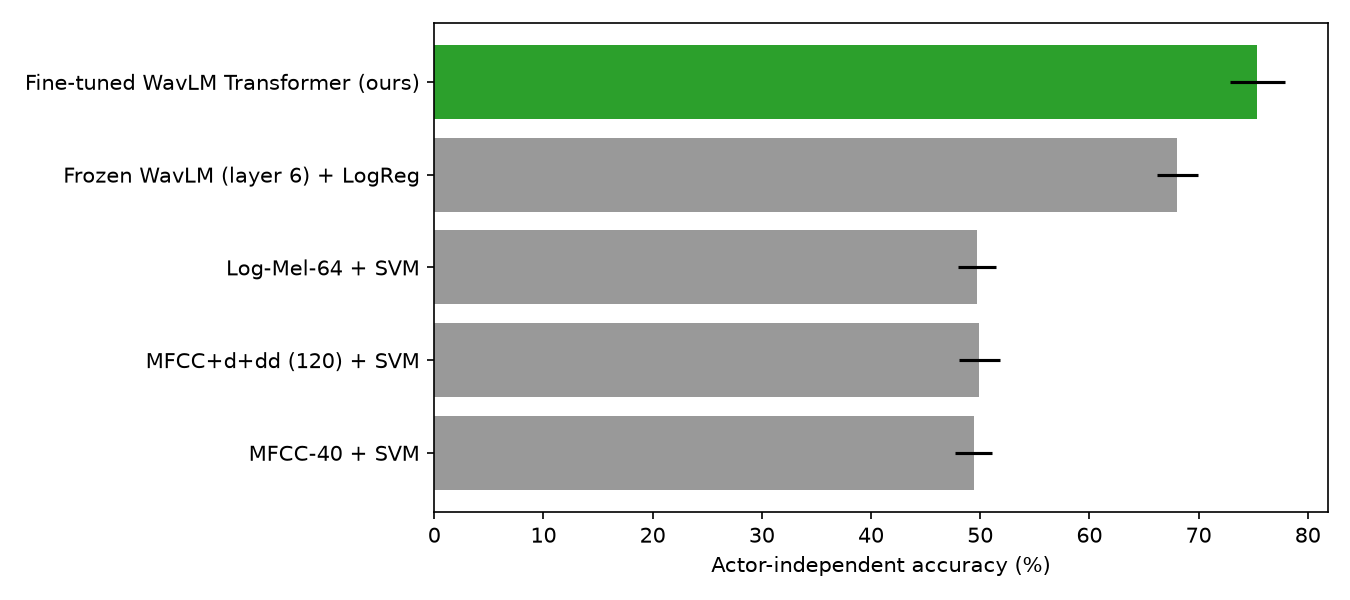

PART 3 DONE. All csv/png outputs are in c:\Users\shrey\Downloads\vedproject/results


In [29]:
rep=[]
p=f"{RES}/final_model_comparison.csv"
if os.path.exists(p): rep.append(pd.read_csv(p).assign(section="model comparison (actor-independent acc %)"))
for name in ["finetune_summary.csv","finetune_per_class_report.csv","feature_selection_comparison.csv","shap_attention_agreement.csv"]:
    q=f"{RES}/{name}"
    if os.path.exists(q): print("\n==",name); display(pd.read_csv(q).round(4))
if rep: display(rep[0].round(2))
show(f"{RES}/final_model_comparison.png") if os.path.exists(f"{RES}/final_model_comparison.png") else None
print("PART 3 DONE. All csv/png outputs are in", RES)

In [30]:
import shutil
shutil.make_archive(f"{BASE}/ser_results","zip",RES); print("zipped ->",f"{BASE}/ser_results.zip")
try:
    from google.colab import files; files.download(f"{BASE}/ser_results.zip")
except Exception as e: print("download manually from the file browser:",e)

zipped -> c:\Users\shrey\Downloads\vedproject/ser_results.zip
download manually from the file browser: No module named 'google.colab'
